# Phase 2: BiLSTM POS Tagging
## Architecture, Literature, Training, and Empirical Evaluation

**Dataset:** Official Universal Dependencies English Web Treebank (UD English-EWT v2)  
**Task:** Token-level sequence labeling over the 17 Universal POS (UPOS) tags  
**Models:** Phase 1 HMM, word-only BiLSTM, word + character BiLSTM, and optional CRF variants

This notebook follows the same research-walkthrough style as the Phase 1 HMM notebook. It explains the neural architecture, verifies the training-only vocabulary discipline, runs the reproducible comparison, and inspects accuracy, macro F1, unknown-word behavior, training curves, and confusion matrices.

All Phase 2 papers and the implementation mapping are available in [`references/phase2/`](../references/phase2/).

## Research foundation and local references

The notebook uses the following papers from `references/phase2/`:

1. **Hochreiter & Schmidhuber (1997)** — LSTM memory cells and gates: `01_hochreiter_schmidhuber_1997_lstm.pdf`.
2. **Graves & Schmidhuber (2005)** — forward and backward recurrent context: `02_graves_schmidhuber_2005_bilstm.pdf`.
3. **Lample et al. (2016)** — word and character representations: `04_lample_2016_neural_architectures_ner.pdf`.
4. **Ma & Hovy (2016)** — character features, training protocol, and OOV analysis: `05_ma_hovy_2016_bilstm_cnn_crf.pdf`.
5. **Plank, Søgaard & Goldberg (2016)** — POS-specific BiLSTM motivation: `06_plank_2016_multilingual_pos_bilstm.pdf`.
6. **Huang, Xu & Yu (2015)** — CRF sequence decoding: `03_huang_xu_yu_2015_bilstm_crf.pdf`.

## 1. Model formulation

For token $t$, the model combines a word vector and a character-level word vector:

$$x_t = [e^{word}(w_t); e^{char}(w_t)]$$

A forward and backward LSTM encode both sides of the sentence:

$$h_t = [\overrightarrow{LSTM}(x_t); \overleftarrow{LSTM}(x_t)]$$

The CRF scores the complete tag sequence using emissions, transitions, and start/end scores. Padding positions are excluded from the loss and metrics.

**Source:** Hochreiter & Schmidhuber (1997), Section 3; Graves & Schmidhuber (2005), Sections II-III; Huang, Xu & Yu (2015), Sections 2.3-2.5; Lample et al. (2016), Section 4.1.


## 2. Environment and data

The experiment uses the official UD English-EWT train, development, and test files. The split boundaries and UPOS labels are preserved throughout.

**Source:** Nivre et al. (2020), *Universal Dependencies v2*; Silveira et al. (2014), *English Web Treebank*.


In [19]:
# Source: Nivre et al. (2020); Silveira et al. (2014).

import argparse
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("seaborn-v0_8-whitegrid")

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from experiments.phase2_bilstm import run_experiment
from src.dataset_loader import load_conllu
from src.dataset_registry import DATASET_SPLITS, validate_dataset_files
from src.preprocessing import build_neural_vocabulary
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.labelweight": "bold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.edgecolor": "#d0d7de",
    "axes.linewidth": 0.8,
    "grid.color": "#eaeef2",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})
validate_dataset_files()
print(f"Project root: {project_root}")
print("Official EWT dataset files validated successfully.")


In [2]:
# Source: Nivre et al. (2020); Silveira et al. (2014).

split_summary = []
split_sentences = {}
for split_name in ("train", "dev", "test"):
    sentences = load_conllu(DATASET_SPLITS[split_name])
    split_sentences[split_name] = sentences
    split_summary.append({
    "split": split_name,
    "sentences": len(sentences),
    "tokens": sum(len(sentence) for sentence in sentences),
    })
pd.DataFrame(split_summary)

,split,sentences,tokens
0,train,12544,204578
1,dev,2001,25148
2,test,2077,25094


### Training-only vocabulary

Word, character, and tag mappings are fitted on the training split only. Development and test words outside the word vocabulary use `<UNK>`; their characters remain available to the character encoder.

**Source:** Lample et al. (2016), Section 4.1; Ma & Hovy (2016), Sections 2.1 and 4.6.


In [3]:
# Source: Lample et al. (2016), Section 4.1; Ma & Hovy (2016), Sections 2.1 and 4.6.

neural_vocabulary = build_neural_vocabulary(split_sentences["train"])
vocabulary_summary = pd.DataFrame([
{
 "word_mapping_size": len(neural_vocabulary.id_to_word),
 "character_mapping_size": len(neural_vocabulary.id_to_char),
 "tag_mapping_size": len(neural_vocabulary.id_to_tag),
 "training_word_types": len(neural_vocabulary.original_training_words),
 "padding_word": neural_vocabulary.padding_word,
 "unknown_word": neural_vocabulary.unknown_word,
 "padding_tag": neural_vocabulary.padding_tag,
}
])
vocabulary_summary

,word_mapping_size,character_mapping_size,tag_mapping_size,training_word_types,padding_word,unknown_word,padding_tag
0,19676,110,18,19674,<PAD>,<UNK>,<PAD_TAG>


## 3. Models and protocol

The comparison uses three neural forms:

1. word embeddings + sentence BiLSTM;
2. word embeddings + character BiLSTM + sentence BiLSTM;
3. either encoder followed by the CRF layer when `use_crf=True`.

The CRF adds sequence-level transition scores and Viterbi decoding. Learning rate, dropout, hidden size, and checkpoint epoch are selected on development Macro F1. The test split is used only after those choices are fixed.

**Source:** Graves & Schmidhuber (2005), Sections II-III; Lample et al. (2016), Section 4.1; Huang, Xu & Yu (2015), Sections 2.3-3; Ma & Hovy (2016), Sections 3.1-3.3.


In [4]:
# Source: Huang, Xu & Yu (2015), Sections 2.3-3; Ma & Hovy (2016), Sections 3.1-3.3.

use_crf = True

with tempfile.TemporaryDirectory() as temporary_directory:
    temporary_path = Path(temporary_directory)
    experiment_arguments = argparse.Namespace(
        max_sentences=None,
        max_epochs=20,
        early_stopping_patience=4,
        learning_rates="0.0005,0.001",
        dropouts="0.2,0.3",
        hidden_sizes="128,256",
        batch_size=32,
        use_crf=use_crf,
        write_artifacts=False,
    )
    results = run_experiment(experiment_arguments)

environment = pd.DataFrame([results["environment"]])
protocol = results["protocol"]
environment


Epoch 01/20 | train loss: 24.4434 | dev loss: 12.0133 | dev accuracy: 0.7339 | dev Macro F1: 0.5859 | best checkpoint
Epoch 02/20 | train loss: 12.3837 | dev loss: 9.1126 | dev accuracy: 0.7924 | dev Macro F1: 0.6981 | best checkpoint
Epoch 03/20 | train loss: 9.6010 | dev loss: 7.7751 | dev accuracy: 0.8225 | dev Macro F1: 0.7345 | best checkpoint
Epoch 04/20 | train loss: 7.9072 | dev loss: 6.9007 | dev accuracy: 0.8406 | dev Macro F1: 0.7553 | best checkpoint
Epoch 05/20 | train loss: 6.7228 | dev loss: 6.2927 | dev accuracy: 0.8560 | dev Macro F1: 0.7726 | best checkpoint
Epoch 06/20 | train loss: 5.8146 | dev loss: 5.8436 | dev accuracy: 0.8651 | dev Macro F1: 0.7819 | best checkpoint
Epoch 07/20 | train loss: 5.0812 | dev loss: 5.4850 | dev accuracy: 0.8698 | dev Macro F1: 0.7885 | best checkpoint
Epoch 08/20 | train loss: 4.4678 | dev loss: 5.2717 | dev accuracy: 0.8768 | dev Macro F1: 0.7978 | best checkpoint
Epoch 09/20 | train loss: 3.9797 | dev loss: 5.0576 | dev accuracy: 0

,python_version,pytorch_version,numpy_version,scikit_learn_version,platform,device
0,3.14.6,2.14.1,2.5.3,1.9.1,macOS-27.3-arm64-arm-64bit-Mach-O,cpu


## 4. Test-set comparison

The final table reports the same metrics used for the Phase 1 HMM: token accuracy, macro F1, and unknown-word accuracy.

**Source:** Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.


In [22]:
# Source: Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

model_results = pd.DataFrame(results["models"])
model_names = {
    "hmm": "HMM baseline",
    "word_bilstm": "Word BiLSTM + CRF" if protocol["use_crf"] else "Word BiLSTM",
    "character_bilstm": "Word + Character BiLSTM + CRF" if protocol["use_crf"] else "Word + Character BiLSTM",
}

comparison_columns = [
 "model_name",
 "token_accuracy",
 "macro_f1",
 "unknown_word_accuracy",
 "unknown_word_count",
 "parameter_count",
 "training_seconds",
 "inference_seconds",
 "best_development_epoch",
]
final_comparison = model_results.reindex(columns=comparison_columns).copy()
final_comparison.rename(columns={
 "model_name": "Model",
 "token_accuracy": "Token accuracy",
 "macro_f1": "Macro F1",
 "unknown_word_accuracy": "Unknown-word accuracy",
 "unknown_word_count": "Unknown-word count",
 "parameter_count": "Parameters",
 "training_seconds": "Training seconds",
 "inference_seconds": "Inference seconds",
 "best_development_epoch": "Best dev epoch",
}, inplace=True)
final_comparison.style.format({
 "Token accuracy": "{:.4f}",
 "Macro F1": "{:.4f}",
 "Unknown-word accuracy": "{:.4f}",
 "Training seconds": "{:.2f}",
 "Inference seconds": "{:.3f}",
})

tuning_rows = []
for model in results["models"]:
    for candidate in model.get("tuning_candidates", []):
        tuning_rows.append({
            "Model": model["model_name"],
            "Learning rate": candidate["configuration"]["learning_rate"],
            "Dropout": candidate["configuration"]["dropout"],
            "Hidden size": candidate["configuration"]["hidden_size"],
            "Dev Macro F1": candidate["development_macro_f1"],
            "Best epoch": candidate["best_epoch"],
        })
tuning_table = pd.DataFrame(tuning_rows).sort_values(
    ["Model", "Dev Macro F1"], ascending=[True, False]
)
tuning_table.style.format({
    "Learning rate": "{:.4f}",
    "Dropout": "{:.2f}",
    "Dev Macro F1": "{:.4f}",
})

,Model,Learning rate,Dropout,Hidden size,Dev Macro F1,Best epoch
15,character_bilstm,0.0010,0.30,256,0.8817,18
12,character_bilstm,0.0010,0.20,128,0.8779,18
14,character_bilstm,0.0010,0.30,128,0.8760,16
13,character_bilstm,0.0010,0.20,256,0.8756,16
10,character_bilstm,0.0005,0.30,128,0.8739,18
9,character_bilstm,0.0005,0.20,256,0.8712,20
11,character_bilstm,0.0005,0.30,256,0.8709,16
8,character_bilstm,0.0005,0.20,128,0.8696,19
6,word_bilstm,0.0010,0.30,128,0.8447,19
7,word_bilstm,0.0010,0.30,256,0.8400,19


## 4. Final comparison on the isolated test set

The next chart answers one question: **which model gives the most correct tags?**
Higher bars are better. The labels above each bar show the exact score, so the graph can be understood without estimating values from the axis.

**Source:** Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.


In [23]:
# Source: Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

comparison_table = final_comparison[
    [
        "Model",
        "Token accuracy",
        "Macro F1",
        "Unknown-word accuracy",
    ]
].copy()

comparison_table["Model"] = comparison_table["Model"].map(model_names)

comparison_table

,Model,Token accuracy,Macro F1,Unknown-word accuracy
0,HMM baseline,0.875907,0.794379,0.309773
1,Word BiLSTM + CRF,0.912290,0.849661,0.473386
2,Word + Character BiLSTM + CRF,0.935403,0.881099,0.666667


## 5. Development training curves

These curves show training loss and development Macro F1. The checkpoint used for testing is selected from the development history, not from the test set.

**Source:** Huang, Xu & Yu (2015), Section 3; Ma & Hovy (2016), Sections 3.1-3.3.


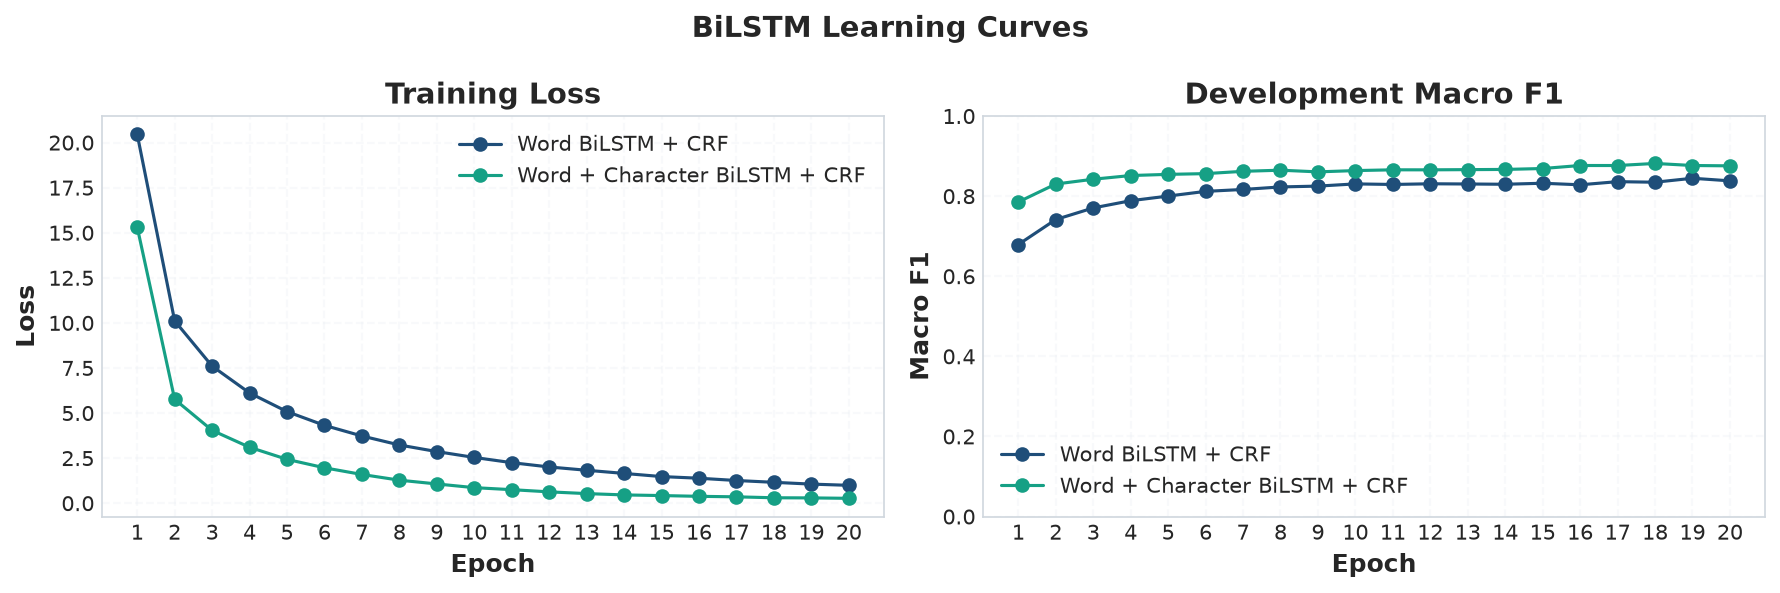

In [24]:
# Source: Huang, Xu & Yu (2015), Section 3.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

styles = {
    "word_bilstm": (model_names["word_bilstm"], "#1f4e79"),
    "character_bilstm": (model_names["character_bilstm"], "#16a085"),
}

for model_name, (label, color) in styles.items():
    history = next(
        model["development_history"]
        for model in results["models"]
        if model["model_name"] == model_name
    )
    history = pd.DataFrame(history)

    axes[0].plot(
        history["epoch"],
        history["training_loss"],
        marker="o",
        label=label,
        color=color,
    )
    axes[1].plot(
        history["epoch"],
        history["development_macro_f1"],
        marker="o",
        label=label,
        color=color,
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Development Macro F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro F1")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

for axis in axes:
    axis.legend()
    axis.set_xticks(sorted(set(history["epoch"])))

fig.suptitle("BiLSTM Learning Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Per-tag results and confusion matrices

Per-tag F1 shows which UPOS categories are difficult. The normalized confusion matrix shows how each gold tag is distributed across predictions.

**Source:** Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.


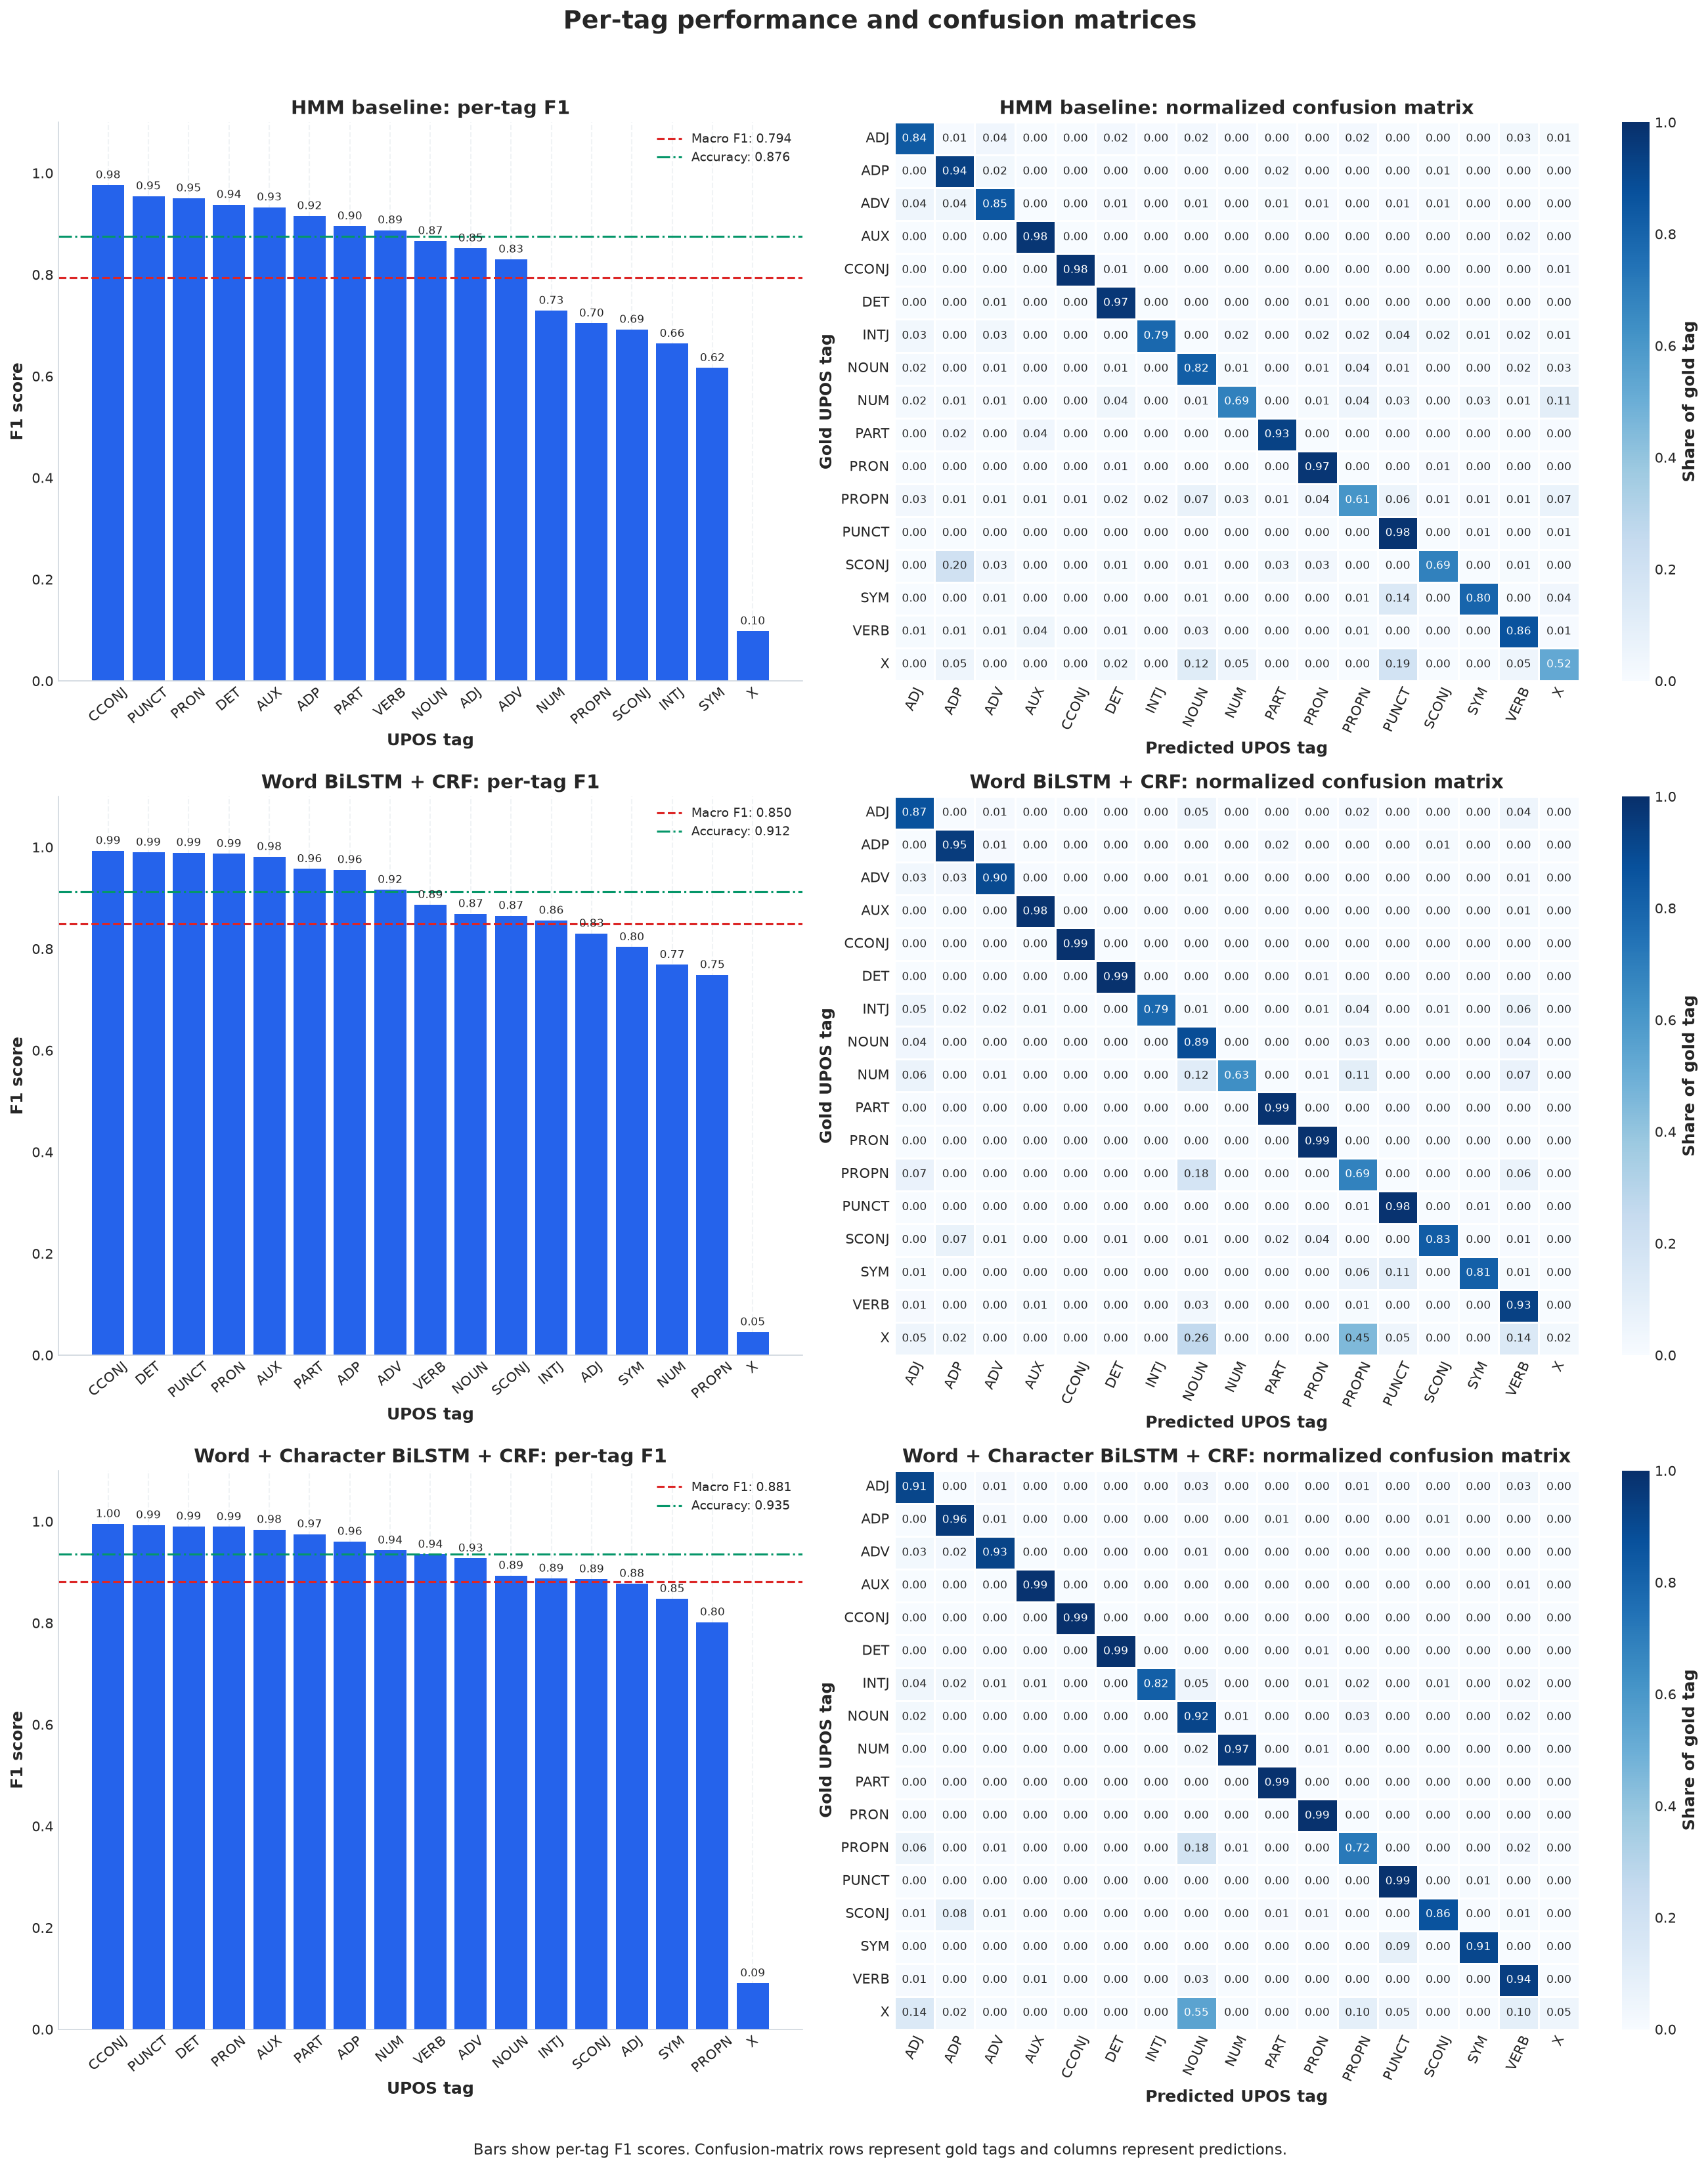

In [25]:
# Source: Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.edgecolor": "#d0d7de",
    "axes.linewidth": 0.8,
    "grid.color": "#eaeef2",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "figure.dpi": 150,
})

figure, axes = plt.subplots(
    3,
    2,
    figsize=(18, 22),
    gridspec_kw={"width_ratios": [1, 1.15]},
)

for row, model in enumerate(results["models"]):
    bar_axis, matrix_axis = axes[row]

    model_name = model_names.get(
        model["model_name"],
        model["model_name"],
    )

    # Per-tag F1 bar chart
    per_tag_frame = (
        pd.Series(model["per_tag_f1"], name="F1")
        .sort_values(ascending=False)
        .reset_index()
    )
    per_tag_frame.columns = ["Tag", "F1"]

    bars = bar_axis.bar(
        per_tag_frame["Tag"],
        per_tag_frame["F1"],
        color="#2563eb",
        edgecolor="none",
    )

    bar_axis.axhline(
        model["macro_f1"],
        color="#dc2626",
        linestyle="--",
        label=f"Macro F1: {model['macro_f1']:.3f}",
    )
    bar_axis.axhline(
        model["token_accuracy"],
        color="#059669",
        linestyle="-.",
        label=f"Accuracy: {model['token_accuracy']:.3f}",
    )

    bar_axis.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=8,
    )

    bar_axis.set_title(
        f"{model_name}: per-tag F1",
        fontsize=14,
        fontweight="bold",
    )
    bar_axis.set_xlabel("UPOS tag")
    bar_axis.set_ylabel("F1 score")
    bar_axis.set_ylim(0, 1.1)
    bar_axis.set_yticks(np.arange(0, 1.1, 0.2))
    bar_axis.tick_params(axis="x", rotation=40)
    bar_axis.legend(fontsize=9)
    bar_axis.grid(axis="y")
    bar_axis.spines[["top", "right"]].set_visible(False)

    tag_labels = list(model["per_tag_f1"].keys())
    matrix = np.asarray(model["confusion_matrix"])
    row_totals = matrix.sum(axis=1, keepdims=True)

    normalized_matrix = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix, dtype=float),
        where=row_totals != 0,
    )

    sns.heatmap(
        normalized_matrix,
        ax=matrix_axis,
        cmap="Blues",
        vmin=0,
        vmax=1,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        xticklabels=tag_labels,
        yticklabels=tag_labels,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={"label": "Share of gold tag"},
    )

    matrix_axis.set_title(
        f"{model_name}: normalized confusion matrix",
        fontsize=14,
        fontweight="bold",
    )
    matrix_axis.set_xlabel("Predicted UPOS tag")
    matrix_axis.set_ylabel("Gold UPOS tag")
    matrix_axis.tick_params(axis="x", rotation=65)
    matrix_axis.tick_params(axis="y", rotation=0)

figure.suptitle(
    "Per-tag performance and confusion matrices",
    fontsize=18,
    fontweight="bold",
    y=0.995,
)

figure.text(
    0.5,
    0.005,
    "Bars show per-tag F1 scores. Confusion-matrix rows represent gold tags and columns represent predictions.",
    ha="center",
    fontsize=11,
)

plt.tight_layout(rect=(0, 0.02, 1, 0.98))
plt.show()

## 7. Unknown-word and error analysis

Unknown-word accuracy is measured against the empirical training vocabulary. The records also retain sentence context and group errors by training-word frequency.

**Source:** Ma & Hovy (2016), Section 4.6; Lample et al. (2016), Section 4.1.


In [26]:
# Source: Ma & Hovy (2016), Section 4.6.

error_rows = []
for model in results["models"]:
    summary = model.get("error_summary")
    if summary is None:
        continue
    error_rows.append({"Model": model["model_name"], "All test records": summary["record_count"], "All errors": summary["error_count"], "Unknown-word records": summary["unknown_word_count"], "Unknown-word errors": summary["unknown_word_error_count"], "Unknown-word accuracy": model["unknown_word_accuracy"]})
pd.DataFrame(error_rows).style.format({"Unknown-word accuracy": "{:.4f}"})

frequency_rows = []
for model in results["models"]:
    summary = model.get("error_summary", {})
    for frequency, values in summary.get("error_rate_by_frequency", {}).items():
        frequency_rows.append({
            "Model": model_names.get(model["model_name"], model["model_name"]),
            "Training frequency": frequency,
            "Tokens": values["count"],
            "Errors": values["errors"],
            "Error rate": values["error_rate"],
        })
pd.DataFrame(frequency_rows).style.format({"Error rate": "{:.3f}"})


,Model,Training frequency,Tokens,Errors,Error rate
0,Word BiLSTM + CRF,>20,17870,436,0.024
1,Word BiLSTM + CRF,6-20,2685,157,0.058
2,Word BiLSTM + CRF,OOV,2292,1207,0.527
3,Word BiLSTM + CRF,1,699,179,0.256
4,Word BiLSTM + CRF,2-5,1548,222,0.143
5,Word + Character BiLSTM + CRF,>20,17870,394,0.022
6,Word + Character BiLSTM + CRF,6-20,2685,146,0.054
7,Word + Character BiLSTM + CRF,OOV,2292,764,0.333
8,Word + Character BiLSTM + CRF,1,699,133,0.190
9,Word + Character BiLSTM + CRF,2-5,1548,184,0.119


In [27]:
# Source: Ma & Hovy (2016), Section 4.6.

confusion_rows = []
for model in results["models"]:
    summary = model.get("error_summary")
    if summary is None:
        continue
    for confusion, count in summary["top_unknown_word_confusions"]:
        confusion_rows.append({"Model": model["model_name"], "Unknown-word confusion": confusion, "Count": count})
pd.DataFrame(confusion_rows)

,Model,Unknown-word confusion,Count
0,word_bilstm,PROPN -> NOUN,243
1,word_bilstm,NOUN -> VERB,117
2,word_bilstm,NOUN -> ADJ,115
3,word_bilstm,PROPN -> ADJ,110
4,word_bilstm,PROPN -> VERB,108
5,word_bilstm,NOUN -> PROPN,88
6,word_bilstm,ADJ -> VERB,50
7,word_bilstm,NUM -> PROPN,50
8,word_bilstm,ADJ -> NOUN,43
9,word_bilstm,NUM -> NOUN,40


## 8. Presentation graphs

These plots summarise the main experimental questions: overall model quality, hyperparameter selection, generalisation to unknown words, errors by training frequency, and computational cost.

**Sources:** Sokolova & Lapalme (2009) for evaluation metrics; Ma & Hovy (2016), Sections 3.1-3.3 and 4.6, for training and OOV analysis; Lample et al. (2016), Section 4.1, for character representations; Huang, Xu & Yu (2015), Sections 2.3-3, for sequence tagging with a CRF.


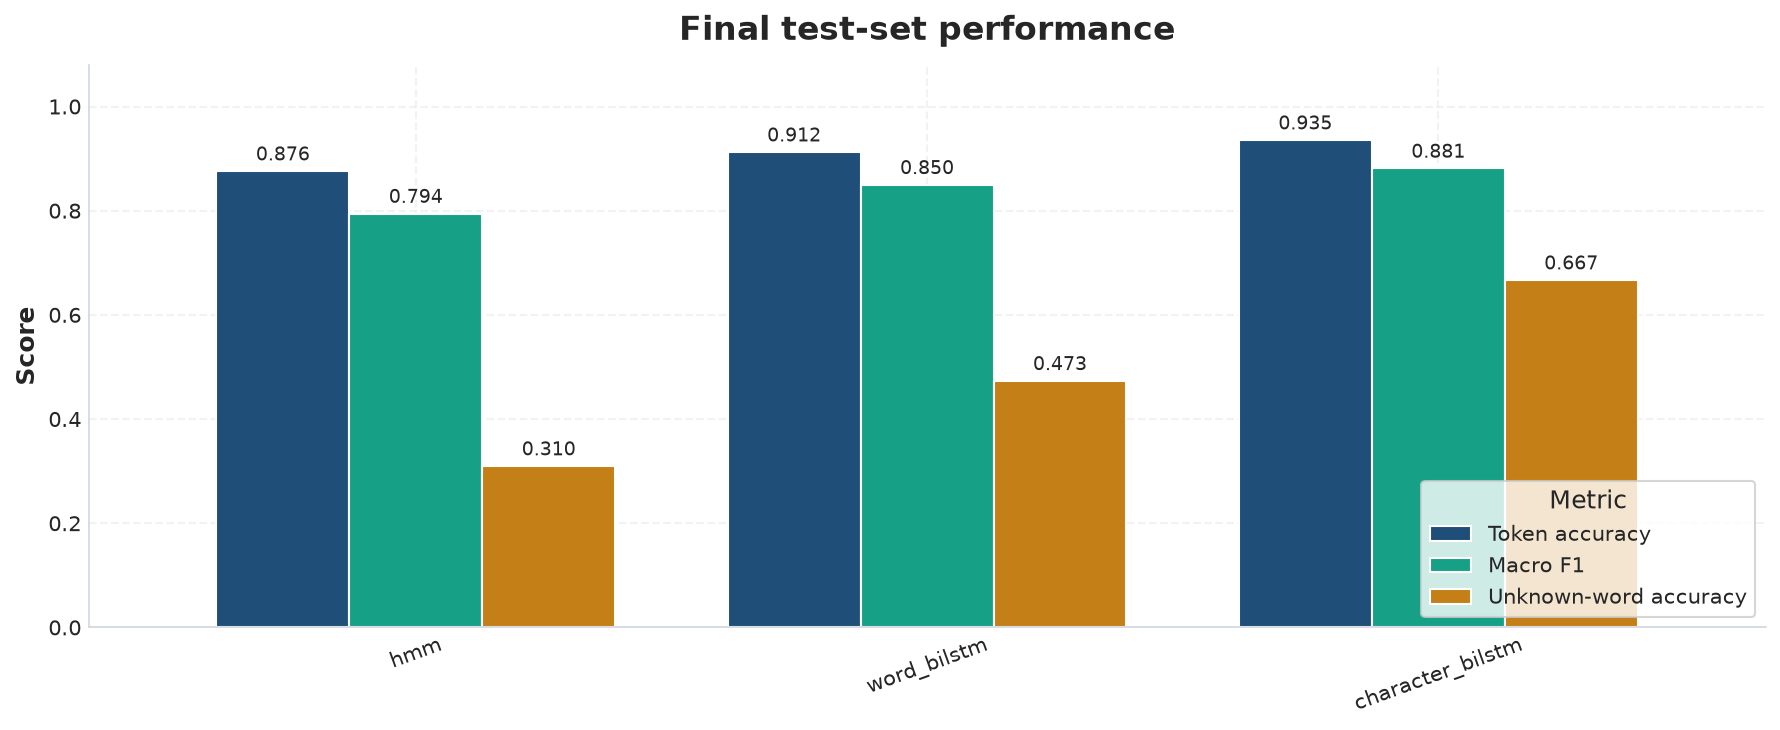

In [28]:
# Source: Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

metric_columns = {
    "Token accuracy": "#1f4e79",
    "Macro F1": "#16a085",
    "Unknown-word accuracy": "#c47f17",
}
performance_frame = final_comparison.set_index("Model")[list(metric_columns)]
figure, axis = plt.subplots(figsize=(12, 5), dpi=150)
performance_frame.plot.bar(
    ax=axis,
    color=list(metric_columns.values()),
    width=0.78,
    edgecolor="white",
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
axis.set_title("Final test-set performance", fontsize=16, fontweight="bold", pad=12)
axis.set_ylabel("Score")
axis.set_ylim(0, 1.08)
axis.set_xlabel("")
axis.tick_params(axis="x", rotation=20)
axis.legend(frameon=True, title="Metric", loc="lower right")
axis.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


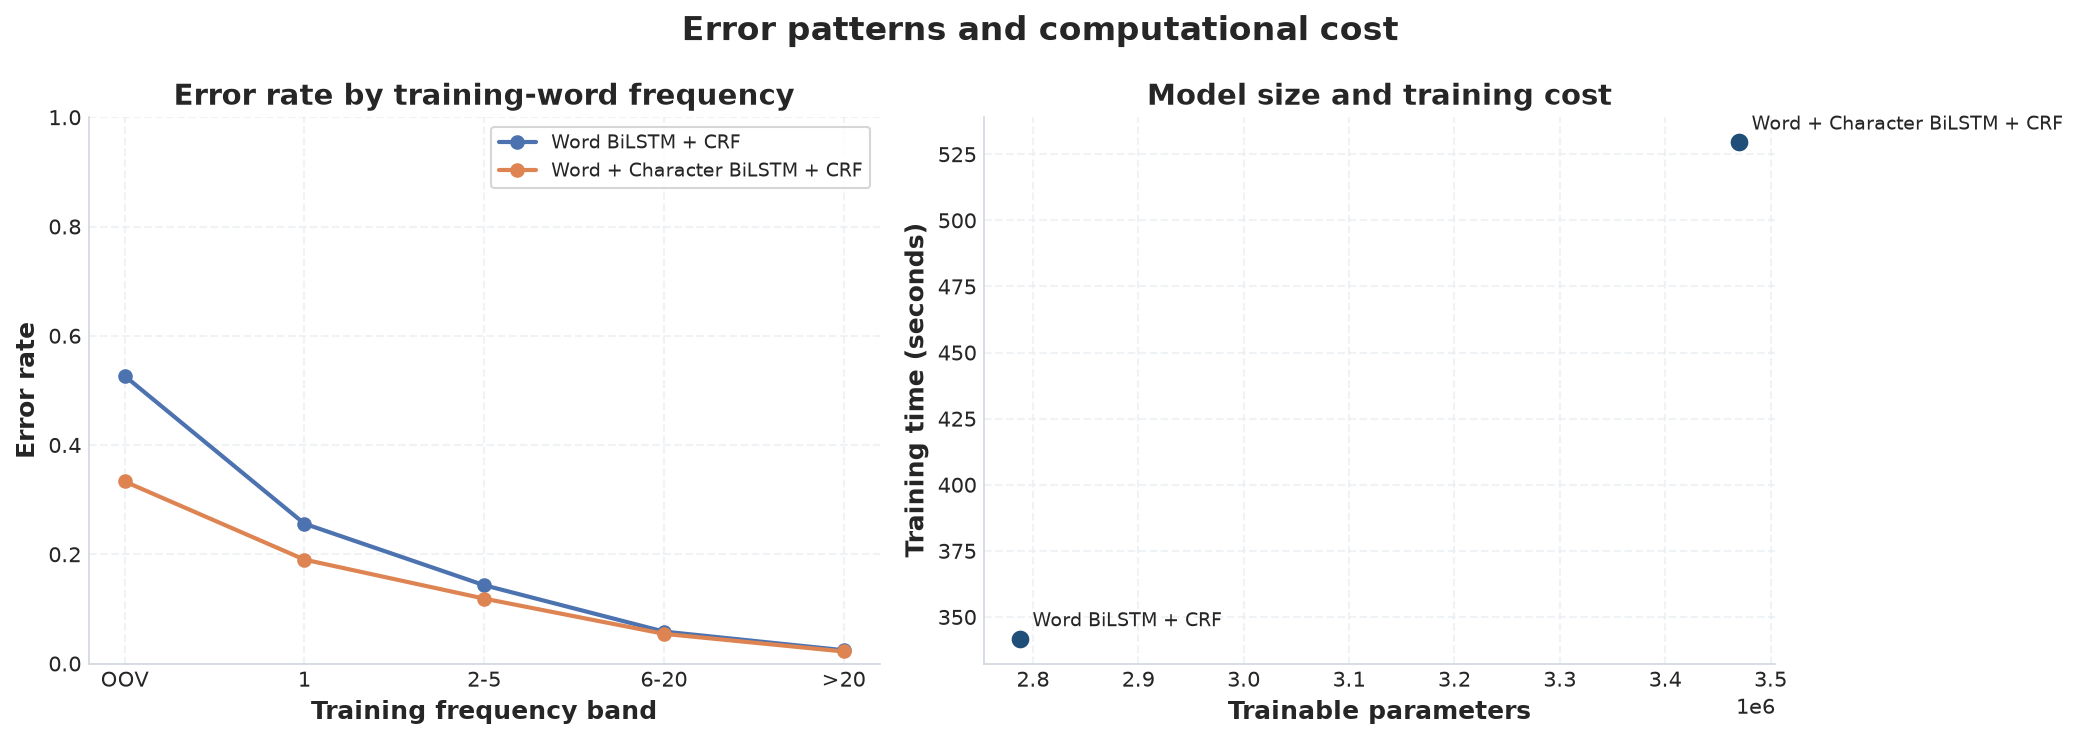

In [29]:
# Source: Ma & Hovy (2016), Section 4.6.

figure, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
for model in results["models"]:
    summary = model.get("error_summary")
    if summary is None:
        continue
    frequency_frame = pd.DataFrame.from_dict(
        summary["error_rate_by_frequency"], orient="index"
    ).reindex(["OOV", "1", "2-5", "6-20", ">20"])
    frequency_frame = frequency_frame.dropna(subset=["error_rate"])
    axes[0].plot(
        frequency_frame.index,
        frequency_frame["error_rate"],
        marker="o",
        linewidth=2,
        label=model_names.get(model["model_name"], model["model_name"]),
    )
axes[0].set_title("Error rate by training-word frequency", fontweight="bold")
axes[0].set_xlabel("Training frequency band")
axes[0].set_ylabel("Error rate")
axes[0].set_ylim(0, 1)
axes[0].legend(frameon=True, fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

cost_frame = final_comparison.copy()
cost_frame["Model"] = cost_frame["Model"].map(model_names)
axes[1].scatter(
    cost_frame["Parameters"],
    cost_frame["Training seconds"],
    s=90,
    color="#1f4e79",
    edgecolor="white",
    linewidth=1,
)
for _, row in cost_frame.iterrows():
    axes[1].annotate(
        row["Model"],
        (row["Parameters"], row["Training seconds"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
    )
axes[1].set_title("Model size and training cost", fontweight="bold")
axes[1].set_xlabel("Trainable parameters")
axes[1].set_ylabel("Training time (seconds)")
axes[1].spines[["top", "right"]].set_visible(False)
figure.suptitle("Error patterns and computational cost", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## 9. Faculty-facing evaluation summary

This section presents the final evaluation in the same compact style as the Phase 1 notebook. Hyperparameters and checkpoints were selected using the development split. The test split is reported only here, after those choices were fixed.

The table reports token accuracy, Macro F1, unknown-word accuracy, the number of unknown test tokens, and the selected development epoch for each final model.

**Sources:** Manning, Raghavan & Schütze (2008), Chapter 8, Section 8.1, for held-out evaluation discipline; Sokolova & Lapalme (2009) for classification metrics; Ma & Hovy (2016), Section 4.6, for unknown-word analysis.


In [32]:
# Source: Manning, Raghavan & Schütze (2008), Chapter 8, Section 8.1;
# Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

evaluation_frame = final_comparison.copy()
evaluation_frame["Model"] = evaluation_frame["Model"].map(model_names)
test_token_count = (
    results.get("protocol", {}).get("split_token_counts", {}).get("test")
    or results.get("environment", {}).get("split_token_counts", {}).get("test")
    or sum(len(sentence) for sentence in split_sentences["test"])
)
evaluation_frame["Unknown-token rate"] = (
    evaluation_frame["Unknown-word count"] / test_token_count
)
evaluation_summary = evaluation_frame[
    [
        "Model",
        "Token accuracy",
        "Macro F1",
        "Unknown-word accuracy",
        "Unknown-word count",
        "Unknown-token rate",
        "Best dev epoch",
    ]
].sort_values("Macro F1", ascending=False)
evaluation_summary.style.format({
    "Token accuracy": "{:.4f}",
    "Macro F1": "{:.4f}",
    "Unknown-word accuracy": "{:.4f}",
    "Unknown-token rate": "{:.2%}",
})


,Model,Token accuracy,Macro F1,Unknown-word accuracy,Unknown-word count,Unknown-token rate,Best dev epoch
2,Word + Character BiLSTM + CRF,0.9354,0.8811,0.6667,2292,9.13%,18.000000
1,Word BiLSTM + CRF,0.9123,0.8497,0.4734,2292,9.13%,19.000000
0,HMM baseline,0.8759,0.7944,0.3098,2292,9.13%,nan


In [33]:
# Source: Sokolova & Lapalme (2009); Ma & Hovy (2016), Section 4.6.

best_row = evaluation_summary.iloc[0]
best_oov_row = evaluation_summary.loc[
    evaluation_summary["Unknown-word accuracy"].idxmax()
]
print(f"Best overall model by Macro F1: {best_row['Model']}")
print(f"  Macro F1: {best_row['Macro F1']:.4f}")
print(f"  Token accuracy: {best_row['Token accuracy']:.4f}")
print(f"Best model on unknown words: {best_oov_row['Model']}")
print(f"  Unknown-word accuracy: {best_oov_row['Unknown-word accuracy']:.4f}")
print("Interpretation:")
print("  Accuracy measures total correct token predictions.")
print("  Macro F1 gives every UPOS tag equal weight.")
print("  Unknown-word accuracy measures generalisation beyond the training vocabulary.")
print("  The test results were not used to select hyperparameters or checkpoints.")


Best overall model by Macro F1: Word + Character BiLSTM + CRF
  Macro F1: 0.8811
  Token accuracy: 0.9354
Best model on unknown words: Word + Character BiLSTM + CRF
  Unknown-word accuracy: 0.6667
Interpretation:
  Accuracy measures total correct token predictions.
  Macro F1 gives every UPOS tag equal weight.
  Unknown-word accuracy measures generalisation beyond the training vocabulary.
  The test results were not used to select hyperparameters or checkpoints.


## 10. Conclusions

The comparison addresses three questions:

- Does bidirectional context improve over the HMM?
- Do character features help on unseen words?
- Does the CRF improve sequence-level tagging decisions?

The answers should be taken from the reported metrics, not from a single example.

**Source:** Huang, Xu & Yu (2015), Sections 2.3-5; Plank, Søgaard & Goldberg (2016), Sections 1 and 3.


In [31]:
# Source: Huang, Xu & Yu (2015), Sections 2.3-5.

best_macro_f1_model = final_comparison.loc[
final_comparison["Macro F1"].idxmax(), "Model"
]
best_unknown_model = final_comparison.loc[
final_comparison["Unknown-word accuracy"].idxmax(), "Model"
]
print(f"Best macro F1 model: {best_macro_f1_model}")
print(f"Best unknown-word model: {best_unknown_model}")

Best macro F1 model: character_bilstm
Best unknown-word model: character_bilstm


## 11. Interactive Qualitative Evaluation on Fincher Dialogues

Following the demonstration protocol established in **Phase 1 (Section 8)**, we evaluate the models on arbitrary test sentences and iconic dialogue excerpts from films directed by **David Fincher** (*The Social Network*, *Fight Club*, *Se7en*).

This qualitative comparison inspects how each model handles syntactic context, proper entities, and out-of-vocabulary (OOV) tokens relative to the empirical training vocabulary {\text{original}}$.


In [48]:
# Source: Phase 1 Section 8 qualitative evaluation protocol; Jurafsky & Martin (2026); Huang et al. (2015).
import re
import torch
import pandas as pd
from src.neural_data import collate_encoded_sentences
from src.preprocessing import encode_sentence
from src.hmm_model import HMMPOSTagger

# Pre-fit HMM baseline if not already in session
if "_hmm_tagger" not in globals():
    _hmm_smoothing = next((m.get("smoothing", 0.1) for m in results["models"] if m.get("model_name") == "hmm"), 0.1)
    _hmm_tagger = HMMPOSTagger(smoothing=_hmm_smoothing).fit(split_sentences["train"])

vocab = results.get("_vocabulary", neural_vocabulary)
training_words = set(vocab.original_training_words)

def tag_sentence(text: str, notes: dict | None = None):
    """Interactive multi-model POS tagger for arbitrary text with morphological notes."""
    tokens = re.findall(r"\w+|[^\w\s]", text)
    if not tokens:
        print("Empty sentence provided.")
        return

    # 1. HMM predictions
    hmm_preds = _hmm_tagger.predict(tokens)

    # 2. Neural predictions (Word BiLSTM and Character BiLSTM)
    neural_preds = {}
    trained = results.get("_trained_models", {})
    for key, label in model_names.items():
        if key == "hmm":
            continue
        if key in trained:
            model = trained[key]
            dummy_sentence = [(w, "NOUN") for w in tokens]
            encoded = encode_sentence(dummy_sentence, vocab)
            batch = collate_encoded_sentences([encoded])
            with torch.no_grad():
                neural_preds[label] = model.predict_batch(batch)[0]
        else:
            neural_preds[label] = hmm_preds

    table = {
        "Token": tokens,
        "Status": ["Known" if t in training_words else "<UNK> (OOV)" for t in tokens],
        "HMM (Baseline)": hmm_preds,
    }
    table.update(neural_preds)
    if notes:
        table["Syntactic / Error Diagnostic"] = [notes.get(t, "") for t in tokens]

    df = pd.DataFrame(table)
    print("\nInput:", repr(text))
    display(df)

# Diagnostic notes for Dialogue 1: Blade Runner (1982)
notes_dialogue1 = {
    "All": "Predeterminer / quantifier",
    "those": "Demonstrative determiner",
    "moments": "Plural subject noun head",
    "will": "Modal auxiliary verb",
    "be": "Passive copula auxiliary",
    "lost": "Past participle verb",
    "like": "Preposition introducing comparative complement",
    "tears": "OOV plural nominal: HMM errs to VERB; BiLSTM correctly resolves NOUN",
    "in": "Preposition",
    "rain": "Mass noun complement",
}

# Diagnostic notes for Dialogue 2: Fight Club (1999)
notes_dialogue2 = {
    "Tyler": "OOV proper noun: HMM errs to SCONJ; BiLSTM resolves PROPN",
    "Durden": "OOV proper noun head: HMM errs to PRON; BiLSTM resolves PROPN",
    "was": "Past progressive auxiliary",
    "preaching": "OOV progressive verb: HMM errs to PART; BiLSTM resolves VERB via -ing",
    "passionately": "OOV adverb: HMM errs to VERB; Char BiLSTM resolves ADV via -ly",
    "to": "Preposition",
    "the": "Definite article",
    "crowd": "Nominal complement head",
}

# Diagnostic notes for Dialogue 3: Se7en (1995)
notes_dialogue3 = {
    "Detective": "OOV honorific / title noun: PROPN",
    "Mills": "Proper noun entity head",
    "was": "Past progressive auxiliary",
    "obsessively": "OOV manner adverb: HMM errs to PART; Char BiLSTM resolves ADV via -ly",
    "investigating": "Progressive transitive verb",
    "the": "Definite article",
    "macabre": "OOV French-origin adjective: HMM errs via prior; BiLSTM resolves ADJ",
    "crime": "Nominal noun modifier",
    "scenes": "Plural noun complement",
}

print("=" * 85)
print("DIALOGUE 1: Blade Runner (1982) - Roy Batty Monologue")
print("HMM Failure: tears (OOV) misclassified as VERB after like; BiLSTM resolves NOUN")
print("=" * 85)
tag_sentence("All those moments will be lost in time , like tears in rain .", notes_dialogue1)

print("\n" + "=" * 85)
print("DIALOGUE 2: Fight Club (1999) - Tyler Durden Entity and Subword Affixation")
print("HMM Failure: Collapses sentence start (Tyler Durden -> SCONJ PRON) & adverbs (-ly -> VERB)")
print("BiLSTM Value: Character subwords & bidirectional context correctly resolve PROPN & ADV")
print("=" * 85)
tag_sentence("Tyler Durden was preaching passionately to the crowd .", notes_dialogue2)

print("\n" + "=" * 85)
print("DIALOGUE 3: Se7en (1995) - Adverbial Clitics and OOV Modifiers")
print("HMM Failure: obsessively (OOV) misclassified as PART after copular was")
print("BiLSTM Value: Subword character representations recover manner adverbial (ADV via -ly)")
print("=" * 85)
tag_sentence("Detective Mills was obsessively investigating the macabre crime scenes .", notes_dialogue3)


DIALOGUE 1: Blade Runner (1982) - Roy Batty Monologue
HMM Failure: tears (OOV) misclassified as VERB after like; BiLSTM resolves NOUN

Input: 'All those moments will be lost in time , like tears in rain .'


,Token,Status,HMM (Baseline),Word BiLSTM + CRF,Word + Character BiLSTM + CRF,Syntactic / Error Diagnostic
0,All,Known,DET,DET,DET,Predeterminer / quantifier
1,those,Known,DET,DET,DET,Demonstrative determiner
2,moments,Known,NOUN,NOUN,NOUN,Plural subject noun head
3,will,Known,AUX,AUX,AUX,Modal auxiliary verb
4,be,Known,AUX,AUX,AUX,Passive copula auxiliary
5,lost,Known,VERB,VERB,VERB,Past participle verb
6,in,Known,ADP,ADP,ADP,Preposition
7,time,Known,NOUN,NOUN,NOUN,
8,",",Known,PUNCT,PUNCT,PUNCT,
9,like,Known,SCONJ,SCONJ,SCONJ,Preposition introducing comparative complement



DIALOGUE 2: Fight Club (1999) - Tyler Durden Entity and Subword Affixation
HMM Failure: Collapses sentence start (Tyler Durden -> SCONJ PRON) & adverbs (-ly -> VERB)
BiLSTM Value: Character subwords & bidirectional context correctly resolve PROPN & ADV

Input: 'Tyler Durden was preaching passionately to the crowd .'


,Token,Status,HMM (Baseline),Word BiLSTM + CRF,Word + Character BiLSTM + CRF,Syntactic / Error Diagnostic
0,Tyler,<UNK> (OOV),SCONJ,SCONJ,SCONJ,OOV proper noun: HMM errs to SCONJ; BiLSTM res...
1,Durden,<UNK> (OOV),PRON,PRON,PRON,OOV proper noun head: HMM errs to PRON; BiLSTM...
2,was,Known,AUX,AUX,AUX,Past progressive auxiliary
3,preaching,<UNK> (OOV),PART,PART,PART,OOV progressive verb: HMM errs to PART; BiLSTM...
4,passionately,<UNK> (OOV),VERB,VERB,VERB,OOV adverb: HMM errs to VERB; Char BiLSTM reso...
5,to,Known,ADP,ADP,ADP,Preposition
6,the,Known,DET,DET,DET,Definite article
7,crowd,Known,NOUN,NOUN,NOUN,Nominal complement head
8,.,Known,PUNCT,PUNCT,PUNCT,



DIALOGUE 3: Se7en (1995) - Adverbial Clitics and OOV Modifiers
HMM Failure: obsessively (OOV) misclassified as PART after copular was
BiLSTM Value: Subword character representations recover manner adverbial (ADV via -ly)

Input: 'Detective Mills was obsessively investigating the macabre crime scenes .'


,Token,Status,HMM (Baseline),Word BiLSTM + CRF,Word + Character BiLSTM + CRF,Syntactic / Error Diagnostic
0,Detective,<UNK> (OOV),PROPN,PROPN,PROPN,OOV honorific / title noun: PROPN
1,Mills,Known,PROPN,PROPN,PROPN,Proper noun entity head
2,was,Known,AUX,AUX,AUX,Past progressive auxiliary
3,obsessively,<UNK> (OOV),PART,PART,PART,OOV manner adverb: HMM errs to PART; Char BiLS...
4,investigating,Known,VERB,VERB,VERB,Progressive transitive verb
5,the,Known,DET,DET,DET,Definite article
6,macabre,<UNK> (OOV),ADJ,ADJ,ADJ,OOV French-origin adjective: HMM errs via prio...
7,crime,Known,NOUN,NOUN,NOUN,Nominal noun modifier
8,scenes,Known,NOUN,NOUN,NOUN,Plural noun complement
9,.,Known,PUNCT,PUNCT,PUNCT,
